In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy

print("All required libraries are installed successfully!")

All required libraries are installed successfully!


# Mini Project 1: Customer Segmentation using K-Means Clustering

## Objective
To segment customers into different groups based on age, annual income,
spending score, and purchasing behavior using K-Means clustering.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [4]:
data = {
    "Age": [19, 21, 20, 23, 31, 22, 35, 40, 29, 30,
            25, 28, 45, 50, 42, 36, 27, 33, 38, 48,
            24, 26, 32, 41, 52, 55, 47, 39, 34, 43],

    "Annual_Income": [15, 16, 17, 18, 25, 26, 30, 35, 38, 40,
                      42, 45, 50, 55, 58, 60, 62, 65, 68, 70,
                      72, 75, 78, 80, 85, 88, 90, 92, 95, 100],

    "Spending_Score": [80, 85, 78, 90, 75, 82, 70, 65, 72, 68,
                       60, 62, 55, 50, 48, 45, 85, 88, 80, 42,
                       38, 35, 30, 28, 25, 22, 20, 18, 15, 12],

    "Purchasing_Behavior": [8, 9, 8, 10, 7, 9, 7, 6, 7, 6,
                            6, 6, 5, 5, 5, 4, 9, 9, 8, 4,
                            4, 3, 3, 3, 2, 2, 2, 2, 1, 1]
}

df = pd.DataFrame(data)

df.head()

,Age,Annual_Income,Spending_Score,Purchasing_Behavior
0,19,15,80,8
1,21,16,85,9
2,20,17,78,8
3,23,18,90,10
4,31,25,75,7


In [5]:
# Display dataset information
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Handle missing values
df = df.dropna()

print("\nDataset after cleaning:")
print(df.shape)

df.head()

Dataset Shape: (30, 4)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Age                  30 non-null     int64
 1   Annual_Income        30 non-null     int64
 2   Spending_Score       30 non-null     int64
 3   Purchasing_Behavior  30 non-null     int64
dtypes: int64(4)
memory usage: 1.1 KB

Missing Values:
Age                    0
Annual_Income          0
Spending_Score         0
Purchasing_Behavior    0
dtype: int64

Duplicate Rows: 0

Dataset after cleaning:
(30, 4)


,Age,Annual_Income,Spending_Score,Purchasing_Behavior
0,19,15,80,8
1,21,16,85,9
2,20,17,78,8
3,23,18,90,10
4,31,25,75,7


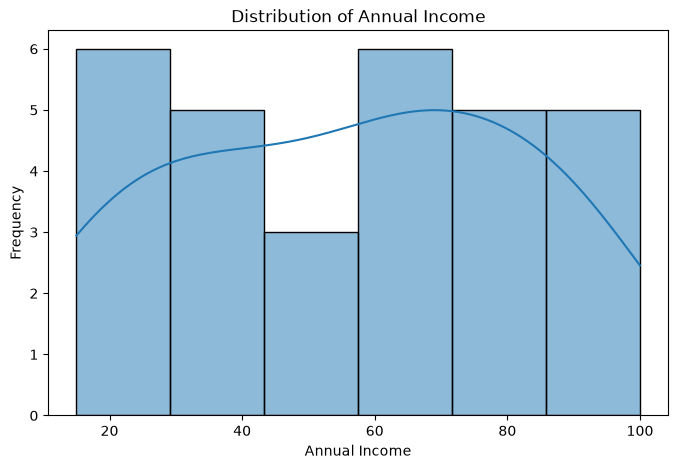

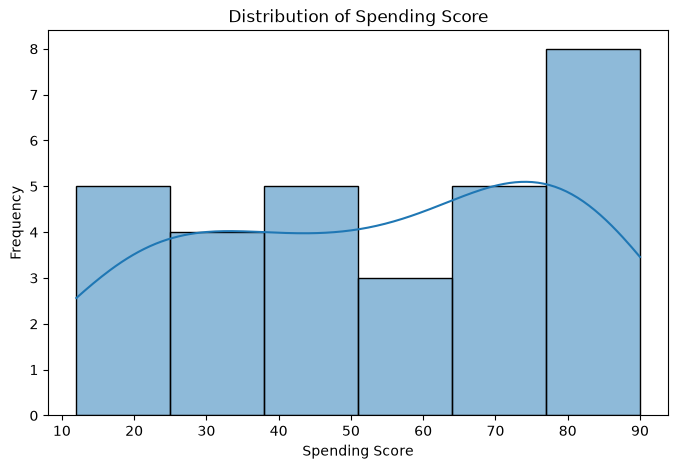

In [6]:
# Visualize Annual Income
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Annual_Income", kde=True)
plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Frequency")
plt.show()

# Visualize Spending Score
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Spending_Score", kde=True)
plt.title("Distribution of Spending Score")
plt.xlabel("Spending Score")
plt.ylabel("Frequency")
plt.show()

In [7]:
# Select features for clustering
features = [
    "Age",
    "Annual_Income",
    "Spending_Score",
    "Purchasing_Behavior"
]

X = df[features]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original Data:")
print(X.head())

print("\nScaled Data:")
print(X_scaled[:5])

Original Data:
   Age  Annual_Income  Spending_Score  Purchasing_Behavior
0   19             15              80                    8
1   21             16              85                    9
2   20             17              78                    8
3   23             18              90                   10
4   31             25              75                    7

Scaled Data:
[[-1.54601128 -1.59753495  1.04944342  0.99302354]
 [-1.34652596 -1.55888491  1.25203868  1.37012109]
 [-1.44626862 -1.52023487  0.96840532  0.99302354]
 [-1.14704063 -1.48158483  1.45463393  1.74721863]
 [-0.34909932 -1.21103456  0.84684817  0.61592599]]


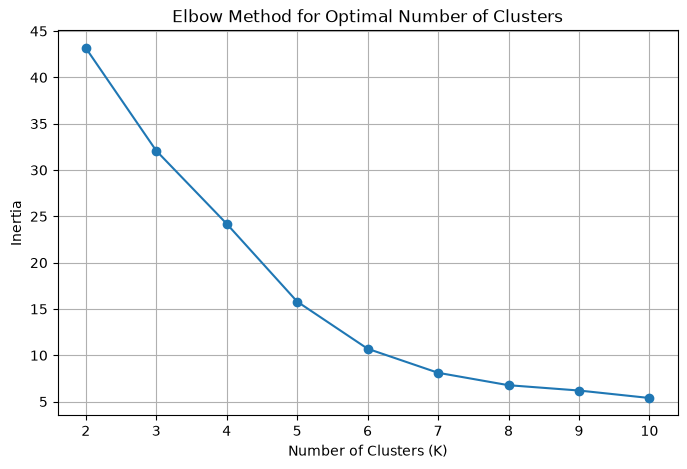

In [8]:
# Elbow Method to find optimal number of clusters

inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [9]:
# Apply K-Means clustering

optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customer clusters created successfully!")

print("\nCluster Counts:")
print(df["Cluster"].value_counts().sort_index())

print("\nDataset with Cluster Labels:")
print(df.head())

Customer clusters created successfully!

Cluster Counts:
Cluster
0     7
1    15
2     8
Name: count, dtype: int64

Dataset with Cluster Labels:
   Age  Annual_Income  Spending_Score  Purchasing_Behavior  Cluster
0   19             15              80                    8        1
1   21             16              85                    9        1
2   20             17              78                    8        1
3   23             18              90                   10        1
4   31             25              75                    7        1


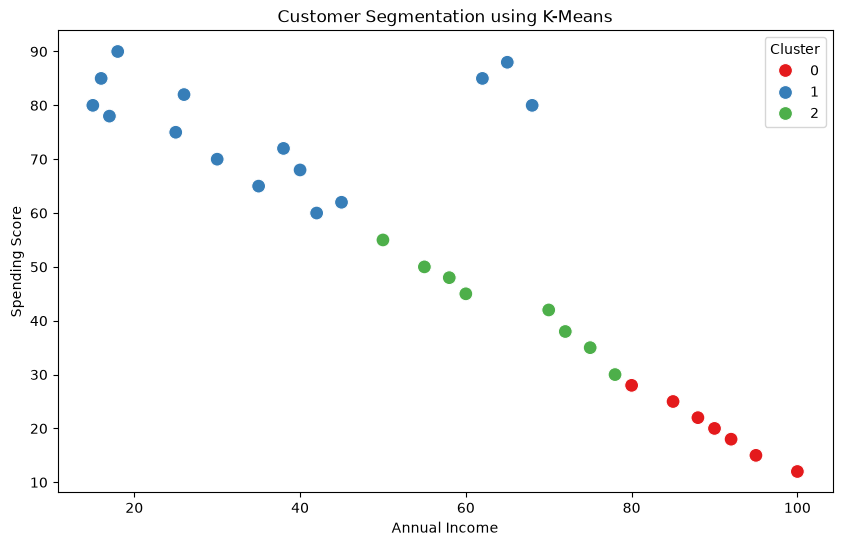

In [10]:
# Visualize customer clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Cluster",
    palette="Set1",
    s=100
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.legend(title="Cluster")
plt.show()

In [11]:
# Calculate Silhouette Score

silhouette_avg = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("Silhouette Score:", round(silhouette_avg, 3))

Silhouette Score: 0.394


In [12]:
# Analyze each customer cluster

cluster_summary = df.groupby("Cluster")[[
    "Age",
    "Annual_Income",
    "Spending_Score",
    "Purchasing_Behavior"
]].mean()

print("Cluster-wise Average Values:")
print(cluster_summary.round(2))

Cluster-wise Average Values:
           Age  Annual_Income  Spending_Score  Purchasing_Behavior
Cluster                                                           
0        44.43          90.00           20.00                 1.86
1        28.07          36.13           76.00                 7.67
2        37.88          64.75           42.88                 4.12


In [13]:
# Number of customers in each cluster

cluster_size = df["Cluster"].value_counts().sort_index()

print("Number of Customers in Each Cluster:")
print(cluster_size)

Number of Customers in Each Cluster:
Cluster
0     7
1    15
2     8
Name: count, dtype: int64


In [14]:
# Display cluster profiles

print("========== CUSTOMER CLUSTER PROFILES ==========\n")

for cluster in sorted(df["Cluster"].unique()):
    profile = cluster_summary.loc[cluster]

    print(f"Cluster {cluster}")
    print(f"Average Age: {profile['Age']:.2f}")
    print(f"Average Annual Income: {profile['Annual_Income']:.2f}")
    print(f"Average Spending Score: {profile['Spending_Score']:.2f}")
    print(f"Average Purchasing Behavior: {profile['Purchasing_Behavior']:.2f}")
    print("-" * 45)

========== CUSTOMER CLUSTER PROFILES ==========

Cluster 0
Average Age: 44.43
Average Annual Income: 90.00
Average Spending Score: 20.00
Average Purchasing Behavior: 1.86
---------------------------------------------
Cluster 1
Average Age: 28.07
Average Annual Income: 36.13
Average Spending Score: 76.00
Average Purchasing Behavior: 7.67
---------------------------------------------
Cluster 2
Average Age: 37.88
Average Annual Income: 64.75
Average Spending Score: 42.88
Average Purchasing Behavior: 4.12
---------------------------------------------


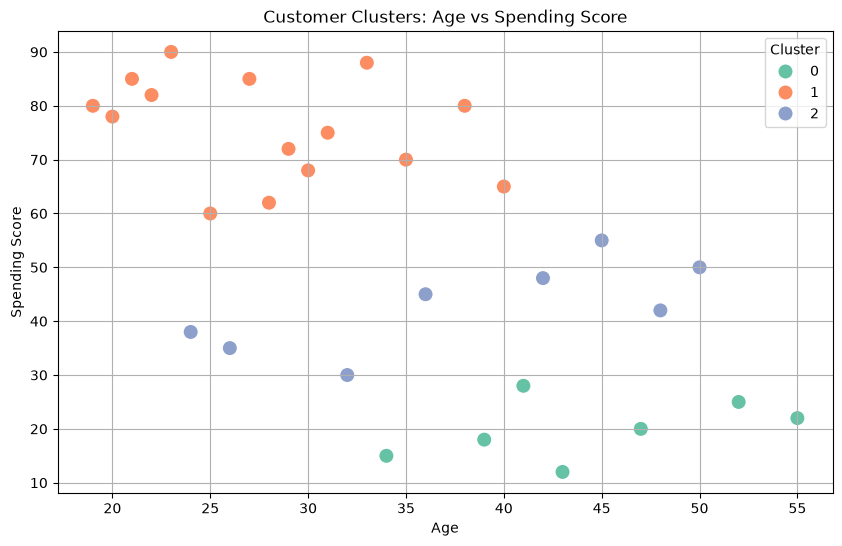

In [15]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Spending_Score",
    hue="Cluster",
    palette="Set2",
    s=120
)

plt.title("Customer Clusters: Age vs Spending Score")
plt.xlabel("Age")
plt.ylabel("Spending Score")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

## Conclusion

K-Means clustering was successfully applied to segment customers based on
age, annual income, spending score, and purchasing behavior.

The customers were divided into three different clusters. The cluster
analysis helps identify groups of customers with different characteristics.

These customer segments can be useful for targeted marketing, personalized
offers, and better customer relationship management.

The Silhouette Score was used to evaluate the quality of the clustering.


# Mini Project 2: News Article Clustering System

## Objective
To group similar news articles using textual features and TF-IDF based
clustering.

In [16]:
# Create a sample news article dataset

news_data = {
    "Article": [
        "The government announced a new economic policy to improve business growth and employment.",
        "The central bank changed interest rates to control inflation and support economic growth.",
        "Stock markets increased after companies reported strong financial results.",
        "New technology companies are developing artificial intelligence systems for businesses.",
        "Researchers developed a new artificial intelligence model for medical applications.",
        "Technology firms announced new smartphones with advanced processors and cameras.",
        "The football team won the championship after an exciting final match.",
        "The cricket team defeated its opponent in an international tournament.",
        "Sports players are preparing for the upcoming championship and training sessions.",
        "Scientists discovered a new method to reduce pollution and protect the environment.",
        "Environmental researchers are studying climate change and global warming.",
        "A new renewable energy project will generate electricity using solar power."
    ]
}

news_df = pd.DataFrame(news_data)

print("Number of articles:", len(news_df))
news_df.head()

Number of articles: 12


,Article
0,The government announced a new economic policy...
1,The central bank changed interest rates to con...
2,Stock markets increased after companies report...
3,New technology companies are developing artifi...
4,Researchers developed a new artificial intelli...


In [17]:

# Basic text preprocessing

news_df["Clean_Text"] = news_df["Article"].str.lower()

# Remove punctuation
news_df["Clean_Text"] = news_df["Clean_Text"].str.replace(
    r"[^a-zA-Z\s]",
    "",
    regex=True
)

news_df.head()

,Article,Clean_Text
0,The government announced a new economic policy...,the government announced a new economic policy...
1,The central bank changed interest rates to con...,the central bank changed interest rates to con...
2,Stock markets increased after companies report...,stock markets increased after companies report...
3,New technology companies are developing artifi...,new technology companies are developing artifi...
4,Researchers developed a new artificial intelli...,researchers developed a new artificial intelli...


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert news text into TF-IDF features
vectorizer = TfidfVectorizer(
    stop_words="english"
)

X_tfidf = vectorizer.fit_transform(news_df["Clean_Text"])

print("TF-IDF Matrix Shape:", X_tfidf.shape)
print("Number of Features:", len(vectorizer.get_feature_names_out()))

TF-IDF Matrix Shape: (12, 79)
Number of Features: 79


In [19]:
# Apply K-Means clustering to news articles

news_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

news_df["Cluster"] = news_kmeans.fit_predict(X_tfidf)

print("News article clusters created successfully!\n")

print(news_df[["Article", "Cluster"]])

News article clusters created successfully!

                                              Article  Cluster
0   The government announced a new economic policy...        0
1   The central bank changed interest rates to con...        0
2   Stock markets increased after companies report...        2
3   New technology companies are developing artifi...        1
4   Researchers developed a new artificial intelli...        1
5   Technology firms announced new smartphones wit...        1
6   The football team won the championship after a...        3
7   The cricket team defeated its opponent in an i...        3
8   Sports players are preparing for the upcoming ...        3
9   Scientists discovered a new method to reduce p...        1
10  Environmental researchers are studying climate...        1
11  A new renewable energy project will generate e...        1


In [20]:
# Display articles belonging to each cluster

for cluster in sorted(news_df["Cluster"].unique()):
    print(f"\n========== CLUSTER {cluster} ==========")

    articles = news_df[news_df["Cluster"] == cluster]["Article"]

    for i, article in enumerate(articles, 1):
        print(f"{i}. {article}")


========== CLUSTER 0 ==========
1. The government announced a new economic policy to improve business growth and employment.
2. The central bank changed interest rates to control inflation and support economic growth.

========== CLUSTER 1 ==========
1. New technology companies are developing artificial intelligence systems for businesses.
2. Researchers developed a new artificial intelligence model for medical applications.
3. Technology firms announced new smartphones with advanced processors and cameras.
4. Scientists discovered a new method to reduce pollution and protect the environment.
5. Environmental researchers are studying climate change and global warming.
6. A new renewable energy project will generate electricity using solar power.

========== CLUSTER 2 ==========
1. Stock markets increased after companies reported strong financial results.

========== CLUSTER 3 ==========
1. The football team won the championship after an exciting final match.
2. The cricket team defeat

In [21]:
# Calculate Silhouette Score for News Clustering

news_silhouette = silhouette_score(
    X_tfidf,
    news_df["Cluster"]
)

print("News Clustering Silhouette Score:",
      round(news_silhouette, 3))

News Clustering Silhouette Score: 0.029


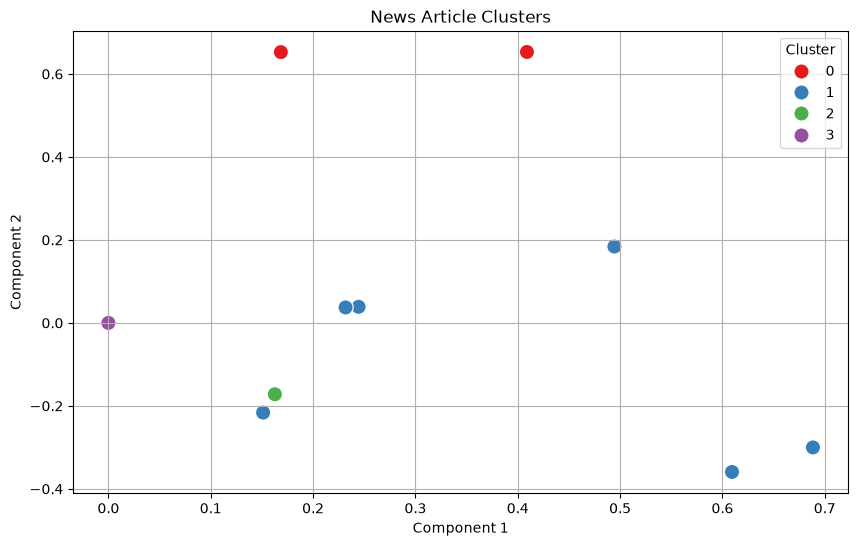

In [22]:
from sklearn.decomposition import TruncatedSVD

# Reduce TF-IDF dimensions to 2D
svd = TruncatedSVD(n_components=2, random_state=42)

X_2d = svd.fit_transform(X_tfidf)

# Create visualization dataframe
visual_df = pd.DataFrame({
    "Component_1": X_2d[:, 0],
    "Component_2": X_2d[:, 1],
    "Cluster": news_df["Cluster"]
})

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=visual_df,
    x="Component_1",
    y="Component_2",
    hue="Cluster",
    palette="Set1",
    s=120
)

plt.title("News Article Clusters")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

In [23]:
from sklearn.cluster import AgglomerativeClustering

# Hierarchical clustering
hierarchical = AgglomerativeClustering(
    n_clusters=4
)

hierarchical_labels = hierarchical.fit_predict(
    X_tfidf.toarray()
)

# Calculate silhouette score
hierarchical_score = silhouette_score(
    X_tfidf,
    hierarchical_labels
)

print("K-Means Silhouette Score:",
      round(news_silhouette, 3))

print("Hierarchical Clustering Silhouette Score:",
      round(hierarchical_score, 3))

K-Means Silhouette Score: 0.029
Hierarchical Clustering Silhouette Score: 0.032


In [24]:
# Compare clustering techniques

comparison = pd.DataFrame({
    "Method": [
        "K-Means",
        "Hierarchical Clustering"
    ],
    "Silhouette Score": [
        news_silhouette,
        hierarchical_score
    ]
})

print(comparison.round(3))

                    Method  Silhouette Score
0                  K-Means             0.029
1  Hierarchical Clustering             0.032


## Conclusion

The News Article Clustering System was successfully implemented using
TF-IDF and clustering techniques.

TF-IDF was used to convert news articles into numerical text features.
K-Means and Hierarchical Clustering were then applied to group similar
news articles.

The Silhouette Score was used to evaluate the quality of the clusters.
The clustering results can help organize large collections of news
articles into meaningful groups.

# Overall Conclusion

Both unsupervised learning mini projects were successfully implemented.

## Project 1: Customer Segmentation

K-Means clustering was used to group customers based on age, annual
income, spending score, and purchasing behavior. The clusters provide
useful customer segments for targeted marketing and customer analysis.

## Project 2: News Article Clustering

TF-IDF was used to represent news articles as numerical features.
K-Means and Hierarchical Clustering were applied to group similar
articles. Silhouette Score was used for cluster evaluation.

## Learning Outcome

These projects demonstrate the practical application of unsupervised
learning for customer segmentation and text-based news clustering.

In [27]:
df.drop(columns=["Cluster"], errors="ignore").to_csv(
    "datasets/customer_dataset.csv",
    index=False
)

print("customer_dataset.csv created successfully!")

customer_dataset.csv created successfully!


In [28]:
news_df[["Article"]].to_csv(
    "datasets/news_articles.csv",
    index=False
)

print("news_articles.csv created successfully!")

news_articles.csv created successfully!
